# 05 Model comparison

All models were evaluated on the same outer folds, so per-fold differences are paired.
This notebook writes the tables and figures used by the revised report.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_curve

from common import FIGURES_DIR, RESULTS_DIR, TABLES_DIR

MODELS = {"logistic_regression": "Logistic regression", "random_forest": "Random forest", "xgboost": "XGBoost"}
METRICS = ["accuracy", "precision", "recall", "specificity", "f1", "auc"]
folds = {m: pd.read_csv(RESULTS_DIR / f"{m}_folds.csv") for m in MODELS}
oof = {m: pd.read_csv(RESULTS_DIR / f"{m}_oof.csv") for m in MODELS}
lr_2024 = pd.read_csv(RESULTS_DIR / "logistic_regression_2024_features_folds.csv")


def table(rule, frames, metrics=METRICS):
    rows = {}
    for name, f in frames.items():
        sub = f[f["rule"] == rule]
        rows[name] = {k: (sub[k].mean(), sub[k].std(ddof=1)) for k in metrics + ["threshold"]}
    return rows


main = table("0.5", {MODELS[m]: folds[m] for m in MODELS})
recall_op = table("recall>=0.90", {MODELS[m]: folds[m] for m in MODELS})
pd.DataFrame({k: {m: f"{v[m][0]:.3f} ± {v[m][1]:.3f}" for m in METRICS} for k, v in main.items()}).T

,accuracy,precision,recall,specificity,f1,auc
Logistic regression,0.833 ± 0.023,0.796 ± 0.030,0.710 ± 0.063,0.900 ± 0.018,0.750 ± 0.042,0.897 ± 0.022
Random forest,0.953 ± 0.014,0.947 ± 0.030,0.921 ± 0.021,0.971 ± 0.017,0.933 ± 0.019,0.956 ± 0.010
XGBoost,0.957 ± 0.009,0.952 ± 0.020,0.927 ± 0.012,0.974 ± 0.011,0.939 ± 0.013,0.958 ± 0.010


## Screening operating point (threshold chosen inside training folds for recall ≥ 0.90)

In [2]:
pd.DataFrame({k: {m: f"{v[m][0]:.3f} ± {v[m][1]:.3f}" for m in METRICS + ["threshold"]}
              for k, v in recall_op.items()}).T

,accuracy,precision,recall,specificity,f1,auc,threshold
Logistic regression,0.778 ± 0.029,0.633 ± 0.035,0.893 ± 0.025,0.715 ± 0.038,0.740 ± 0.030,0.897 ± 0.022,0.261 ± 0.013
Random forest,0.953 ± 0.014,0.947 ± 0.030,0.921 ± 0.021,0.971 ± 0.017,0.933 ± 0.019,0.956 ± 0.010,0.490 ± 0.021
XGBoost,0.954 ± 0.011,0.957 ± 0.021,0.912 ± 0.016,0.977 ± 0.011,0.934 ± 0.016,0.958 ± 0.010,0.556 ± 0.025


## Paired per-fold differences

In [3]:
def paired(a, b, metric):
    fa = folds[a][folds[a]["rule"] == "0.5"].set_index("fold")[metric]
    fb = folds[b][folds[b]["rule"] == "0.5"].set_index("fold")[metric]
    d = fa - fb
    return {"mean": d.mean(), "sd": d.std(ddof=1), "min": d.min(), "max": d.max()}


diffs = {f"{MODELS[a]} − {MODELS[b]} ({m})": paired(a, b, m)
         for a, b in [("xgboost", "logistic_regression"), ("xgboost", "random_forest")]
         for m in ["accuracy", "auc"]}
pd.DataFrame(diffs).T.round(4)

,mean,sd,min,max
XGBoost − Logistic regression (accuracy),0.1243,0.0201,0.0963,0.1400
XGBoost − Logistic regression (auc),0.0607,0.0133,0.0409,0.0734
XGBoost − Random forest (accuracy),0.0040,0.0064,-0.0033,0.0133
XGBoost − Random forest (auc),0.0015,0.0075,-0.0069,0.0098


## ROC curves and pooled confusion matrices (out-of-fold predictions)

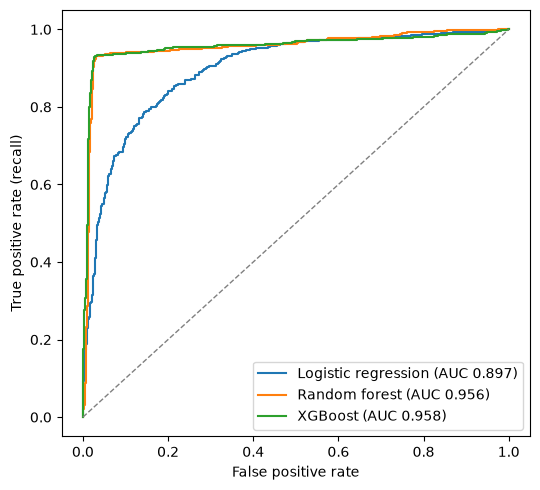

logistic_regression pred_05 [[875, 97], [154, 378]]
logistic_regression pred_recall [[695, 277], [57, 475]]
random_forest pred_05 [[944, 28], [42, 490]]
random_forest pred_recall [[944, 28], [42, 490]]
xgboost pred_05 [[947, 25], [39, 493]]
xgboost pred_recall [[950, 22], [47, 485]]


In [4]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for m, label in MODELS.items():
    fpr, tpr, _ = roc_curve(oof[m]["y"], oof[m]["prob"])
    ax.plot(fpr, tpr, label=f"{label} (AUC {main[label]['auc'][0]:.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "roc_comparison.png", dpi=150)
plt.show()

cms = {}
for m in MODELS:
    for col in ("pred_05", "pred_recall"):
        cms[(m, col)] = confusion_matrix(oof[m]["y"], oof[m][col], labels=[0, 1])
        print(m, col, cms[(m, col)].tolist())

## LaTeX tables for the report

In [5]:
def fmt(mean, sd):
    return f"${mean:.3f} \\pm {sd:.3f}$"


def latex_rows(rows, metrics):
    return "\n".join(name + " & " + " & ".join(fmt(*rows[name][k]) for k in metrics) + " \\\\"
                     for name in rows)


(TABLES_DIR / "main_results.tex").write_text(latex_rows(main, METRICS) + "\n")
(TABLES_DIR / "recall_operating_point.tex").write_text(
    "\n".join(f"{n} & ${v['threshold'][0]:.2f}$ & " + " & ".join(fmt(*v[k]) for k in ["recall", "specificity", "precision", "accuracy"]) + " \\\\"
              for n, v in recall_op.items()) + "\n")

lr_old = {k: (lr_2024[lr_2024["rule"] == "0.5"][k].mean(), lr_2024[lr_2024["rule"] == "0.5"][k].std(ddof=1)) for k in METRICS}
summary = {
    "main": {n: {k: v[k][0] for k in METRICS} for n, v in main.items()},
    "main_sd": {n: {k: v[k][1] for k in METRICS} for n, v in main.items()},
    "recall_operating_point": {n: {k: v[k][0] for k in METRICS + ["threshold"]} for n, v in recall_op.items()},
    "lr_2024_features": {k: v[0] for k, v in lr_old.items()},
    "paired_differences": diffs,
    "pooled_confusion": {f"{m}/{c}": cm.tolist() for (m, c), cm in cms.items()},
}
(RESULTS_DIR / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print((TABLES_DIR / "main_results.tex").read_text())
print((TABLES_DIR / "recall_operating_point.tex").read_text())

Logistic regression & $0.833 \pm 0.023$ & $0.796 \pm 0.030$ & $0.710 \pm 0.063$ & $0.900 \pm 0.018$ & $0.750 \pm 0.042$ & $0.897 \pm 0.022$ \\
Random forest & $0.953 \pm 0.014$ & $0.947 \pm 0.030$ & $0.921 \pm 0.021$ & $0.971 \pm 0.017$ & $0.933 \pm 0.019$ & $0.956 \pm 0.010$ \\
XGBoost & $0.957 \pm 0.009$ & $0.952 \pm 0.020$ & $0.927 \pm 0.012$ & $0.974 \pm 0.011$ & $0.939 \pm 0.013$ & $0.958 \pm 0.010$ \\

Logistic regression & $0.26$ & $0.893 \pm 0.025$ & $0.715 \pm 0.038$ & $0.633 \pm 0.035$ & $0.778 \pm 0.029$ \\
Random forest & $0.49$ & $0.921 \pm 0.021$ & $0.971 \pm 0.017$ & $0.947 \pm 0.030$ & $0.953 \pm 0.014$ \\
XGBoost & $0.56$ & $0.912 \pm 0.016$ & $0.977 \pm 0.011$ & $0.957 \pm 0.021$ & $0.954 \pm 0.011$ \\

